# Robustness of the logical S gate for [[4,1,2]] code


In this notebook, we construct a circuit to check the robustness of a logical S gate in for the [[4,1,2]] code. 

The code has the following stabilizer generators:

\begin{equation}
    \mathcal{S} = \langle X_0X_1X_2X_3, Z_0Z_1I_2I_3, I_0I_1Z_2Z_3 \rangle,
\end{equation}

And its logical operators are:
\begin{align}
    & \bar{X} = X_0X_1I_2I_3, \\
    & \bar{Z} = I_0Z_1Z_2I_3.
\end{align}

Then, the logical states of the code can be, for exmaple, denoted as:
\begin{align}
    & \bar{\ket{0}} = \frac{1}{\sqrt{2}}(\ket{0000}+ \ket{1111})\\
    & \bar{\ket{1}} = \frac{1}{\sqrt{2}}(\ket{1100}+ \ket{0011})
\end{align}

We know that the logical S gate is $\bar{S} = \bar{\sqrt{Z}}$. Therefore, the derivation yields:

\begin{equation}
    \bar{S} = I_0 (S_1\otimes S_2)CZ_{(1,2)} I_3,
\end{equation}
whare $S_i$ is the single-qubit S gate on the $i$-th qubit and $CZ_{(i,j)}$ is the controlled Z gate on the qubits $i$ and $j$.

In [1]:
import stim

# 1. Robustness with no encoding 

We are first going to familiarize ourselves with the stim library. We first construct the circuit without any encoding, to check the robustness of the S gate via Bell basis measurement.

In [3]:
#Defining the circuit to check the robustness of S without encoding 

circuit = stim.Circuit()

#Creation of Bell pair
circuit.append_operation("H",0)
circuit.append("CNOT", [0, 1])
circuit.append_operation("S", [0,1])
circuit.append("CNOT", [0, 1])
circuit.append_operation("H",0)
circuit.append("M", [0, 1])

print(repr(circuit))


stim.Circuit('''
    H 0
    CX 0 1
    S 0 1
    CX 0 1
    H 0
    M 0 1
''')


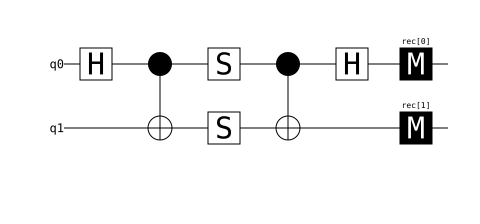

In [7]:
#Checking how the circuit looks like

circuit.diagram('timeline-svg')

In [ ]:
#Checking robustness without encoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]]


## Explanation

The Bell states and the final measurement outcomes they correspond to are:

\begin{align}
    &\ket{\Phi^+} = \frac{1}{\sqrt{2}}(\ket{00} + \ket{11}) \rightarrow 00,\\ 
    &\ket{\Phi^-} = \frac{1}{\sqrt{2}}(\ket{00} - \ket{11}) \rightarrow 10,\\
    &\ket{\Psi^+} = \frac{1}{\sqrt{2}}(\ket{01} + \ket{10}) \rightarrow 01,\\
    &\ket{\Psi^-} = \frac{1}{\sqrt{2}}(\ket{01} - \ket{10}) \rightarrow 11.
\end{align}

At the beginnig, we generate the $\ket{\Phi^+}$ Bell state. The application of S gates on each qubit transforms the state to $\ket{\Psi^+}$, giving us the outcomes 0,1 in the measurement. The result is the same in every trial, because we do not have encoding, decoding and errors. 

In conclusion, when we will be checking for robstness (and fidelity) in the final circuit with logical S, we will be intererested in the percentage of trials where we obtain the $\ket{\Psi^+}$ at the end.

# 2. Encoder and Decoder 

We write down a circuit to encode a state with [[4,1,2]] code and subsequently, to decode it.

stim.Circuit('''
    H 2
    CX 2 0 0 1 2 3
    M 0 1 2 3
''')


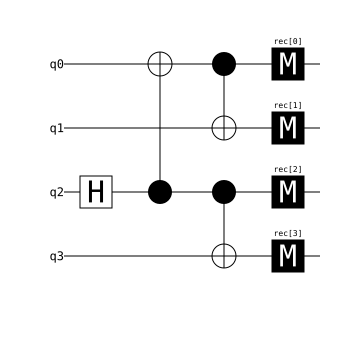

In [15]:
#Encoder
circuit = stim.Circuit()
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])
circuit.append("M", [0, 1,2,3])



print(repr(circuit))
circuit.diagram('timeline-svg')

In [14]:
#Sampling the circuit with encoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[False False  True  True]
 [ True  True False False]
 [ True  True False False]
 [False False  True  True]
 [False False  True  True]
 [False False  True  True]
 [ True  True False False]
 [False False  True  True]
 [ True  True False False]
 [False False  True  True]]


stim.Circuit('''
    H 2
    CX 2 0 0 1 2 3 2 3 0 1 2 0
    H 2
    M 0 1 2 3
''')


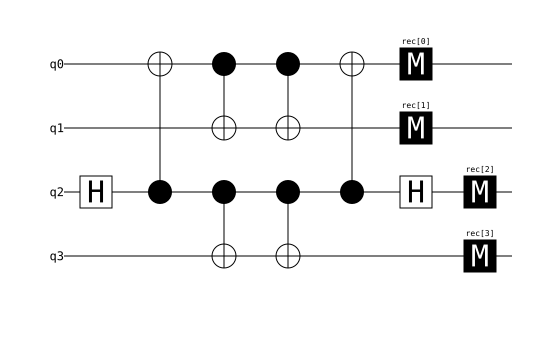

In [23]:
#Encoder + Decoder (encoder in reversed order)

circuit = stim.Circuit()


#Encoder
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])

#Decoder
circuit.append("CNOT", [2, 3])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 0])  
circuit.append_operation("H",2)

#Measurement
circuit.append("M", [0, 1,2,3])

print(repr(circuit))
circuit.diagram('timeline-svg')

In [24]:
#Sampling the circuit with encoding and decoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]]
